# Variant 28: Fitness app retention
**Student: Bakhtiyar Makashev Sagandykovich · AI Fundamentals**

All observations and labels are **synthetic**. This notebook is standalone and does not import Streamlit or require a running website. In Google Colab, use **File → Upload notebook**, then **Runtime → Run all**. Outputs saved in this file were obtained by actual sequential local Python execution in the project environment, not by a Google-hosted Colab run. Rich Plotly outputs render in compatible notebook viewers. Different package versions can change numerical results; the archived data hash remains fixed.

## Part 2: Unsupervised learning and anomalies


## Step 1 — Tools and research question
Find groups, low-dimensional structure, and unusual observations without using the known activity target. Analysis is exploratory on the entire cohort, using its own preprocessing fit.


In [1]:
# Install only missing packages. This cell is safe in Colab and local Python.
import importlib.util, subprocess, sys
packages = {"numpy": "numpy>=1.26,<3", "pandas": "pandas>=2.2,<3", "sklearn": "scikit-learn>=1.6,<2", "plotly": "plotly>=5.24,<7"}
MISSING = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if MISSING:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *MISSING])
import io, json, hashlib, base64, zlib, platform
from pathlib import Path
from importlib.metadata import version
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from itertools import combinations
from sklearn.base import clone
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE, trustworthiness
from sklearn.metrics import (accuracy_score, adjusted_rand_score, classification_report, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score, roc_curve, silhouette_score)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
FEATURES = ["workouts", "streak", "notifications"]
TARGET = "active_next_week"
SEED = 42
print("Python:", platform.python_version())
print({name: version(name) for name in ["numpy", "pandas", "scikit-learn", "plotly"]})

if importlib.util.find_spec("umap") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "umap-learn>=0.5.7,<0.6"])
def show_chart(fig):
    fig.update_layout(template="plotly_white", height=460, margin=dict(l=30, r=30, t=70, b=40))
    display(fig)

def show_map(embedding, labels, title):
    view = pd.DataFrame({"axis_1": embedding[:, 0], "axis_2": embedding[:, 1], "group": np.asarray(labels).astype(str)})
    show_chart(px.scatter(view, x="axis_1", y="axis_2", color="group", title=title, opacity=.7))
def prepare(strategy: str='median', scaled: bool=True) -> Pipeline:
    """Fresh preprocessing for each fit; unsupervised analysis never reuses supervised fit."""
    return Pipeline([('imputer', SimpleImputer(strategy=strategy, keep_empty_features=True)), ('scaler', StandardScaler() if scaled else 'passthrough')])

def safe_silhouette(values: np.ndarray, labels: np.ndarray) -> float:
    groups = len(np.unique(labels))
    return float(silhouette_score(values, labels)) if 1 < groups < len(values) else float('nan')


Python: 3.14.6
{'numpy': '2.5.5', 'pandas': '2.3.3', 'scikit-learn': '1.9.1', 'plotly': '6.9.0'}


## Step 2 — Dataset provenance and feature dictionary
The exact archived table is embedded so numerical results can be audited without regenerating a different sample. The original generator is included below for transparency, but model training uses the embedded snapshot. Workouts and notifications are Poisson-like counts, streak is Gamma-derived, and three overlapping generator regimes are discarded. Labels are Bernoulli draws from the documented noisy nonlinear activity function. Missing values are independently introduced after labels (MCAR). These are assumptions, not observed real user relationships. No real personal data are present.


In [2]:
# Embed the exact archived synthetic data: no upload, API key, app.py, or internet dataset is needed.
ARCHIVED_CSV = zlib.decompress(base64.b64decode("eJx1XM2OpbeN3edZbgKJFEXpJWaTVVaGkfQADQM2YHeSefz56koiD3nlRRnoUypK4p+OSH3+9x/ffv/p+79e//3t919++/ePP15//Pj928+/vH797cf3//3+z59/fP/t1z9eP//zx/f/fPvp12//9+On/3779stf/v6P//lrKaW+2t/Ki5+f/vzUA9OLnn/O50cQ5jdcv/7jYHuVL7B+/afgaHmPbucvysH7e66557Xhuv75JUIRH2+cMzxf7xnPnxzpde1k7J8zvFYbLg2H01sq1aSBurYqe2Yb3tZGOWusytroh5y+tJOVUPWNjT3c4PGGXzXImK6VNuEXVGyRjtXXe6CCVKItVRDkZdsjwQS010v6MdwB5a2GlrRKsDtUE+l7/pmUQeM9/P0nYSnTxaCNuZjpcTjX97Z1L8bgZcqS/Ir5LZjOGg1vjqNSWV7vfQasu7OhWlh94ej6PN4Llo85l9O2PGfbMs4vz5ZafW9J0nIavZbdcC1tB2dNgdJWfFJWbpO3bXpSV+vLwi3jurZz1mJLHK5GdKMGWyXAZW21ZJeRGpdpOPquCVl7Dc4lbS2wYjTIY8yZtCd9zfKxAjWFrGR28GXMkPRkRhkH72WvFqOkL3+l5K+dDAqjl79q9qneLE2jPvvKspyluMcGWC2OUXcdjBiET1t58Hst7gwoXquHHxpRyVSLgay8p8tZU5vFFaF6Vcx5BLOpdk8saDrVGOM2fp0p+XzTlYdOljujx9oRnZR2hg+3K252kPkG7mmsfKvzLPTgzfYUhIt7GJpkQCqqOKtaQkSLjGEGD8fkmPesOEF0mHfWmLsNJ0shOO9knxO3NZt7WRgvFv5oqLkMO/4Wc9pUM1TwyzlcORjaE/wYlFbLMlGzTHXwlXebWeDgZAcuxmZ9iFF5h30Q3jxICAd74lWEuwUyoxQ1EtIRHq4BQdztisLr/ueRbnhdrh2tVB9WdDvXa2V3goC390p0izJY3BwB72tW88CD6/rnySE2foQD34ZPI5iomocVuRgDfaNo0IcZsYUAegCxH0dB+NppSqCVxB1McXh3koX2IL2eQZU8EaM9NkHKebgyHLzoBVzdfqixhyItx0Zs56W0QqRHYbiYL+IKN0Mars3zi3WqZrpSH4rUbnLmGpVM3Up0SMPrNWgegtS2SnDOhyL1G9x8GegcTUywY90TOxq6aUzXhg+/XGHGeOjRK52edVMjY5lHxkON5GC4biHPgKhDYT+F0XelGeHA1F4FnHfi+O6MKqxTLZZ87PAbGu7zIUp4ezvDu4cQhlEHv0UNdPJMJzie48XBxjfTJKE1HrJ0chQqbJOlj7T2sKVxFIBe1xcjZM3Ln/fl69o8H8cz/Lmr5TtFVXLijN6oi/N+eN7DlU5ixPhVP1DDAbGpEuW9PlTp8B5UzcOU3owzW+qhSueajQZ5qJKdBIYt9w0afDjSPGJx85skcRbh9gRiVh+OtDYRltCtpIEbGXBVQ32M4bZHdT8EaXkyRtD0VBPS0KweibiWSR6JOOmEOylqdS5bfkGOiZ/0aPcJnBedaqpxlLCU4Ukk4O6zEONUSmTU5eB1aeV9dgv+AdmWGGH2yA3y3aLohlTEmX/B8d3TdphW4zlt+LidI1SmbwvF12KXLlx9dYaPMUqVnPAGMcmuZ1fVY5RwuB8wNeDdgmgi7GcMDZQ+rocj1RWjmnf1RZD0zHmEUDXhE+GVeSmFEz386FatI3IPRsWQXL2Mut1nUb0ERkXno3XInDkNnr7GYCYu0ckMd9YQ9M4rK9nFxfCVlXKRkLgZn3BM9t+eg8Z+0dcvWgnD1w01aIWH36BR5zzBcVE0sCPUS1tZKSz5YUYnwQoOXY6bbnHU2q1yQbt0lFMvndrRPEo/uNqENeDDyFRD8R6kglEkxaMx4NVOP1SXrK1SSZuSlZLiWC84BFiueZqkW+AGyWr0At1QhkNon4cbfZzPtCtI+fgnoEYYnw8zqrbBMN4tiqVGeqjREoQGfXjROBHkI4EpoHm6Rydh6PcRyZjhfk0L0anFVxjwumtoGPqbFdm5YDhfyyG0WVEqWJPK1aEfUnSyFpp5l4+MMxi+SNFbhZhXHlJkdkANDF8IbnR4TyKkm0HXUigNvqfFARVeTOm7hHR4molfbDcRBBp/cpIOqKlg0hnO7IPjzV0DyOPnooGJ8dEk9wLU5WQnngFfm00lcZqr/9JSSY/msizlqi7NfS9NPQqawwM1zDtXwozyubgiB8J+woAFubgXY0jxZkmJw/MmSZLhc8Qkh+LS7WIWxi83nlgZ5+KFwYljoS4IEcK1XOOM6zpjsrW5kh32qIDKMaIMb87LCHExHMOed1vNrrg2rV4LVFw9BU+Epyk4LGc31ig1QZhWXZCS0/AuI6Vsww9JevWRPJuBIoXB4iGJcLfuQw24OkkISxm3ojTTNKqCrsFQV0HpXK2AgqmJGQqD6B7MFhk4K68SaEtBzCzXDMe8HBhrOcxqoURhKdeiIO8W23s4imneccaQaamsbcPJu3RhPPuBhf6+mdKHwprYYYMKaP2WmrmtSOWaZx3u7mFT0wgHihFIwRg1sqyayh8sZMMbGlVWsAaHkWaO4Zg3+tETN0n68H9ZlQZKGZbFM1IQM83OOPrhSR+Ekh+S9L47o2W6X0yRNTLWjjCj9ea3LLRk98saKq+vu1pQ0u6y5fR8ykZZwrwe36xbd6lEyurt7zgeDhc040OR1k5x97q6iZ+DF+NdWQv3pD3wT4PV6uFoHR3eoDXR86rAAVvBCUfdBZgQTw83eltL0l2MB5tvh4NoNPP3IF3u1h+LL4QMNNTTr+Aux3B2jKRgU6NcU+K5E0FJa59uUVzjTF0Yw32rGPWzeWka3Q4LSJjiZjd+EoarxVqAvTPhEua1Vd0K+AkhXq/t2FbIqCHjcK94KsLtyiHa7qtlVtTKupVyIrytQEVQUc5+vNGznBkJ8hlft/uXNH4/OTqM1IbTXWlYO6qIN+8+ozKrN4gnwj3uynCg92E5w/szqPwK76uAqjZaSw+a3LWjFAaN7pm3EWReVBh5y8kxaIOjVh5aVG8l10bQGmacdPhznDB+3hfJ+8hJl/nG1R+M4YIYqg0dcXfiAC9mRD0tB5gREt7G/RrEjeGKGpY/vMWKbvDQo/zar7VznqP9W7U1D4TJ+6hw+LTm7+Vwuv34KPP01hIBNLx76xadvfnbHMeGk2W0xH55lO8ATYrNaWOlOlNC9Yk/gAxBKvzREmzSYqQYLn+CQ4SiKXf1qKbM23b5yDqoNn5aSRxV2MuNirdeb33b1s/zqiCC/UhG54S2WtBWF7ACqquDOcME/qghjh9rmP3y4POeG9WLwRG/HqhtP0PKHKHtIpLlDMPb3cM0vc05eng40qfbqW6Xw43q8HcBGF7qZDfMuElSDq9RvQcRcHq94qE2oF4fJcPNG71uyF3loxvxQD8aapwkLGTcs+uY91MHG2w462mwJdbXJplOArxPmJL1O//Egx+OlN+TtocfZV7bdnPt4/Cew9JfmG46JQMxUoBfFcSrbx+yv+y6EZsuD85+qE3Emxfcw3hxPMwLcRp/oZ5LCRc01m2a8oKm3XzADaRC4QzXWWt0D8Ppow8qFaqfqMuHH310s+UhRx9OJEiNBg6GolEYPwL/tOFz5+j8vFfonFwnVu0XUDdC9RLZzCYe2REcD0IN9o62IDhLG+LQIA6CdOcGtBANr5OiQe91I8G6Ec7JFZ66oGqYYoq1P+BXvicLey0liJD9yG4g2F9WCzaZalGETnXaal8/YS9zP63p2Q0buCwqpa1StqTikHy9yz6lwbOYUzA6uzd8bbKl1CXIjMKc/cax5bw7+sD9WUNYzUpIIVlIsVY5qkW8shtG00UCvz6onEizCx3uD1gR2ky6le18qN7jVYb5EmpoF4qI0ozdO3IBrp7aMLw7lFECzlbFwxDenCi7yK4WeVY9eA8NKIMXIaKsrT6cn2LY9BlP7YOrc1xcO77LxnNF99cv6Ymq7LdG51ix4e0Oy9p+Xrx2cyr0FtVrCVU2J5o5CnXeuI+M4h1BFDOqLTAMd6aAa3940YqddI+WXTeibKmxyvRs+jy4PzvCxY97kUHGuBb9ZEx/moCBO8vd4A8xeqeW/JZWprckMC/gyyNUz/SqZ5hWouPY8B671DZeTfmozLlT78irARoIWuvFW2eKsJsWFtm/2NHb4yWLYa8+B9wPmIHw6oK3VCjqpZsaA7wvMSOLSc9xbJkTupygzF6L8QxCuFq/Chdf4U1ZwHfDNDlmf/jRuInxAqitsPoZg2qv/qKshgXeG/69wm0NFUbwPCzg9eY0nTwRA33p5HkYt0nrHpOYZ99dtbqYwwG7MwHcEHmrKeLpFmP4tBjDOXn7Q2pZdK6vjxf4fX+1NjLMVxrQeW2zz2Nq+8XXW0h/CnJQP26CL7K+rD9rY4ddDnCT7M830GgNHjWj1Vp9fTyA6G09rOKskf3syJrZhrcYQoZLcAmD93Ocj2kh+WLCaPCkAXXY5u31acd2GtpC/JsCxuWI18jQcXftqObbVxe4gk/8g9PnT8XDvslSoPV9t9U41fO7QJQWHD+fK28qHPTu9scJkSvhnPsTto/h92fZfbfWssv0VCiz4d16S2HSFaW95lnXFaalymzH/hoqQMGD0fm0fmZGJaPSaCHl63uAvrtrlCXL9VhT+CAR3XT31sgevh58eHkO9ahQskeFAVOKuLNC3NSge9QMJ4XBTKN5MQP1vp8ffbg7fMGGqx/7A9N0IepjxPaKTetMCTPbPA8eMVInvLRC2ZO8BhNwvrL3vllSAsXuFpgFprf40dj70zV3rf0we+QlwPMqIIha7jdv3V/y51qlFrh4d8Q5WMHEtJVxNUWRfj06WrezIKW/MtPW4g3EAA+zV5AwLcDBG7QW9wbUtn6VjM6B2xCn8OD77KeuXimnYoKertqMIar1+qG77tJRpkC6qRHlzdb7vU2rOy3ulqDVj6uk6v6DmyWyJCIIu01RB/DgKAiHz36CcH9FFnG1K3pYu3/UrzjpvJYgdVeOTmI3GN6RBZw+krEyfIUIlw9lf9OA28fHRgVxZ7txyvurT2V3YKS7uglSenmordzqJ9rgkwKU0shwjMf9yVpuW2rzQraPFds/RtiuHFGqtWuDfWKkN/+UC0OgzVuHTwWeQcO6pZqzIINTgbetqPSvElKme7o/WEsFBBWxlIELlHuLVAVYfZC+DhaytHnwueuMcPhp99MczdD35zDt4xdQRcIE0J3xOubvdwkXcj7tNy89eL8yOu1/YtB+b8Iofq6G47WEWoDBzouwNa2bG9WSi76qbJdaNJTi/0QljL9/s6a630BmD96VpJ7lO713bFriwqHD3QiTFDCj4KUPNRrH2gHnGwXQAV+Ah1nlmpCHP7hHd99f9i/TIX4vIekmRqn0q9MPWbTqPN8gooj9KDtxF53+ytOxdrcZfNDPYRk9ZmOTA1Ea8GGJJATH/m4tv4IbxSnGyqP/D/QIlhQ="))
EXPECTED_HASH = "d0526e53c4a5929c8808f73065a2c8cd1eedb00146d18171a476dfe29f0369ed"
assert hashlib.sha256(ARCHIVED_CSV).hexdigest() == EXPECTED_HASH
frame = pd.read_csv(io.BytesIO(ARCHIVED_CSV))
assert frame.shape == (800, 5) and frame.user_id.is_unique
assert set(frame[TARGET].unique()) == {0, 1}
print("SYNTHETIC inputs and target labels; dataset SHA-256 verified.")
print("Shape:", frame.shape)
display(frame.head())
display(frame[FEATURES].describe().T)
display(pd.DataFrame({"missing": frame.isna().sum(), "missing_fraction": frame.isna().mean()}))
print("Class balance:", frame[TARGET].value_counts().to_dict())


SYNTHETIC inputs and target labels; dataset SHA-256 verified.
Shape: (800, 5)


,user_id,workouts,streak,notifications,active_next_week
0,SYN-0001,4.0,3.0,6.0,1
1,SYN-0002,2.0,9.0,5.0,1
2,SYN-0003,2.0,12.0,NaN,1
3,SYN-0004,0.0,11.0,10.0,1
4,SYN-0005,2.0,4.0,12.0,0


,count,mean,std,min,25%,50%,75%,max
workouts,760.0,2.884211,2.734113,0.0,1.0,2.0,4.0,14.0
streak,770.0,8.666234,13.741966,0.0,2.0,4.0,9.0,110.0
notifications,771.0,9.892348,6.194684,0.0,6.0,9.0,13.0,56.0


,missing,missing_fraction
user_id,0,0.00000
workouts,40,0.05000
streak,30,0.03750
notifications,29,0.03625
active_next_week,0,0.00000


Class balance: {1: 560, 0: 240}


In [3]:
def generate_data(n: int=800, seed: int=42, missing: float=0.05) -> pd.DataFrame:
    """Generate reproducible synthetic inputs AND labels; never present as real logs."""
    if not 600 <= n <= 1000 or not 0 <= missing <= 0.2:
        raise ValueError('n must be 600–1000; missing must be 0–0.20')
    rng = np.random.default_rng(seed)
    mode = rng.choice(3, n, p=[0.38, 0.42, 0.2])
    workouts = np.clip(rng.poisson(np.array([0.8, 3.1, 6.0])[mode]), 0, 14).astype(float)
    streak = np.clip(np.rint(rng.gamma(1.7, np.array([1.0, 4.0, 12.0])[mode])), 0, 120)
    notifications = np.clip(rng.poisson(np.array([14.0, 8.0, 4.0])[mode]), 0, 60).astype(float)
    unusual = rng.choice(n, max(1, int(n * 0.03)), replace=False)
    for i, idx in enumerate(unusual):
        if i % 3 == 0:
            workouts[idx], streak[idx] = (rng.integers(0, 2), rng.integers(60, 121))
        elif i % 3 == 1:
            notifications[idx] = rng.integers(35, 61)
        else:
            workouts[idx], streak[idx] = (rng.integers(10, 15), rng.integers(40, 91))
    z = -2 + 0.55 * workouts + 0.9 * np.log1p(streak) + 0.07 * np.minimum(notifications, 10) - 0.06 * np.maximum(notifications - 10, 0) - 0.1 * np.maximum(workouts - 9, 0) ** 2 + rng.normal(0, 0.75, n)
    target = rng.binomial(1, 1 / (1 + np.exp(-np.clip(z, -30, 30))))
    values = np.column_stack([workouts, streak, notifications])
    values[rng.random(values.shape) < missing] = np.nan
    frame = pd.DataFrame(values, columns=FEATURES)
    frame.insert(0, 'user_id', [f'SYN-{i + 1:04d}' for i in range(n)])
    frame[TARGET] = target
    return frame


## Step 3 — Three exploratory plots
Histograms use the full 800-user exploratory cohort and exclude NaN. Long tails and different units affect distances.


In [4]:
for feature in FEATURES:
    show_chart(px.histogram(frame, x=feature, nbins=30, title=f"Exploratory distribution: {feature}"))
print("Only these features will enter unsupervised fitting:", FEATURES)
assert TARGET not in FEATURES and "user_id" not in FEATURES


Exploratory distribution: workouts

Exploratory distribution: streak

Exploratory distribution: notifications

Only these features will enter unsupervised fitting: ['workouts', 'streak', 'notifications']


## Step 4 — Preprocessing and fair scaling comparison
Use median imputation and standardization for the primary fit. The raw/scaled comparison holds K and seed fixed; scores describe different geometries.


In [5]:
X = frame[FEATURES].copy()
pre = prepare()
Z = pre.fit_transform(X)
print("Standardized means:", Z.mean(axis=0))
print("Standardized population SDs:", Z.std(axis=0))
comparison=[]
for strategy in ["median", "mean"]:
    for scaled in [False, True]:
        A = prepare(strategy, scaled).fit_transform(X)
        labels = KMeans(n_clusters=2, n_init=10, random_state=SEED).fit_predict(A)
        comparison.append({"imputer": strategy, "scaled": scaled, "K":2, "silhouette": safe_silhouette(A, labels)})
display(pd.DataFrame(comparison))


Standardized means: [ 4.05231404e-17 -8.43769499e-17  1.02140518e-16]
Standardized population SDs: [1. 1. 1.]


,imputer,scaled,K,silhouette
0,median,False,2,0.728298
1,median,True,2,0.445683
2,mean,False,2,0.725720
3,mean,True,2,0.433940


## Step 5 — K-Means assignments and profiles
The model operates in standardized 3D. Original-unit profiles use observed values and are not exactly inverse-transformed imputed centroids.


In [6]:
km = KMeans(n_clusters=2, n_init=10, random_state=SEED).fit(Z)
km_labels = km.labels_
print("Cluster counts:", pd.Series(km_labels).value_counts().sort_index().to_dict())
profiles = X.assign(cluster=km_labels).groupby("cluster").mean()
display(profiles)
print("Manual centroid example, first three imputed rows:", pre.named_steps["imputer"].transform(X)[:3].mean(axis=0))
profile_plot = profiles.reset_index().melt(id_vars="cluster", var_name="feature", value_name="mean")
show_chart(px.bar(profile_plot, x="cluster", y="mean", facet_col="feature", title="Cluster profiles in original units").update_yaxes(matches=None))


Cluster counts: {0: 236, 1: 564}


,workouts,streak,notifications
cluster,,,
0,5.987069,20.722944,5.555066
1,1.520833,3.499072,11.702206


Manual centroid example, first three imputed rows: [2.66666667 8.         6.66666667]


Cluster profiles in original units

## Step 6 — Elbow, silhouette, and seed stability
K=2 maximizes silhouette and gives simple profiles. The elbow is ambiguous and does not independently prove K=2. Stability across seeds checks initialization, not resampling.


In [7]:
search=[]
for k in range(2,9):
    m = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)
    search.append({"K":k, "inertia":m.inertia_, "silhouette":safe_silhouette(Z,m.labels_)})
search=pd.DataFrame(search)
display(search)
for metric in ["inertia","silhouette"]:
    show_chart(px.line(search,x="K",y=metric,markers=True,title=f"K selection: {metric}"))
selected_k=int(search.loc[search.silhouette.idxmax(),"K"])
assert selected_k == 2
stability=[]
for seed in [0,1,2,3,4,42]:
    m=KMeans(n_clusters=selected_k,n_init=10,random_state=seed).fit(Z)
    stability.append({"seed":seed,"inertia":m.inertia_,"silhouette":safe_silhouette(Z,m.labels_),"ARI_vs_reference":adjusted_rand_score(km_labels,m.labels_)})
display(pd.DataFrame(stability))


,K,inertia,silhouette
0,2,1537.942262,0.445683
1,3,1149.227552,0.383609
2,4,883.351052,0.414784
3,5,666.198947,0.370506
4,6,551.608593,0.364435
5,7,479.839809,0.367932
6,8,422.966310,0.319001


K selection: inertia

K selection: silhouette

,seed,inertia,silhouette,ARI_vs_reference
0,0,1537.942262,0.445683,1.0
1,1,1537.942262,0.445683,1.0
2,2,1537.942262,0.445683,1.0
3,3,1537.942262,0.445683,1.0
4,4,1537.942262,0.445683,1.0
5,42,1537.942262,0.445683,1.0


## Step 7 — DBSCAN and sensitivity
Noise is excluded when calculating silhouette. A single remaining cluster produces NaN intentionally.


In [8]:
def density_analysis(Z: np.ndarray, eps: float, min_samples: int) -> dict:
    labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(Z)
    rows = []
    for e in sorted(set([0.4, 0.7, 1.0, round(eps, 2)])):
        for ms in sorted(set([3, 5, 8, min_samples])):
            lab = DBSCAN(eps=e, min_samples=ms).fit_predict(Z)
            mask = lab != -1
            rows.append({'eps': e, 'min_samples': ms, 'clusters': len(set(lab) - {-1}), 'noise': int((~mask).sum()), 'noise_fraction': float((~mask).mean()), 'silhouette_without_noise': safe_silhouette(Z[mask], lab[mask])})
    return dict(labels=labels, sensitivity=pd.DataFrame(rows))
db = density_analysis(Z, .7, 5)
db_labels = db["labels"]
display(db["sensitivity"])
print("Default clusters:", len(set(db_labels)-{-1}), "Noise:", int((db_labels==-1).sum()))
assert int((db_labels==-1).sum()) == 42


,eps,min_samples,clusters,noise,noise_fraction,silhouette_without_noise
0,0.4,3,9,79,0.09875,0.085764
1,0.4,5,2,110,0.13750,0.360093
2,0.4,8,1,133,0.16625,NaN
3,0.7,3,3,32,0.04000,0.612483
4,0.7,5,1,42,0.05250,NaN
5,0.7,8,1,49,0.06125,NaN
6,1.0,3,4,8,0.01000,0.637259
7,1.0,5,2,21,0.02625,0.765249
8,1.0,8,1,29,0.03625,NaN


Default clusters: 1 Noise: 42


## Step 8 — PCA, variance and loadings
PCA is linear. The first two components retain 81.1137% of standardized variance; the remaining component is omitted from the map.


In [9]:
pca = PCA().fit(Z)
P = pca.transform(Z)[:,:2]
display(pd.DataFrame({"component":["PC1","PC2","PC3"], "explained_variance":pca.explained_variance_ratio_, "cumulative":np.cumsum(pca.explained_variance_ratio_)}))
display(pd.DataFrame(pca.components_[:2],columns=FEATURES,index=["PC1","PC2"]))
show_map(P,km_labels,"PCA: linear projection")
show_map(P,db_labels,"DBSCAN in PCA; -1 = noise")
assert np.isclose(pca.explained_variance_ratio_[:2].sum(),.8111369752170252)


,component,explained_variance,cumulative
0,PC1,0.568283,0.568283
1,PC2,0.242854,0.811137
2,PC3,0.188863,1.000000


,workouts,streak,notifications
PC1,0.616535,0.547936,-0.565376
PC2,-0.067610,0.752289,0.655355


PCA: linear projection

DBSCAN in PCA; -1 = noise

## Step 9 — t-SNE and perplexity sensitivity
Compare local neighborhoods at perplexities 30 and 10. These maps do not preserve all global distances or validate the cluster count. min_dist is not a t-SNE parameter.


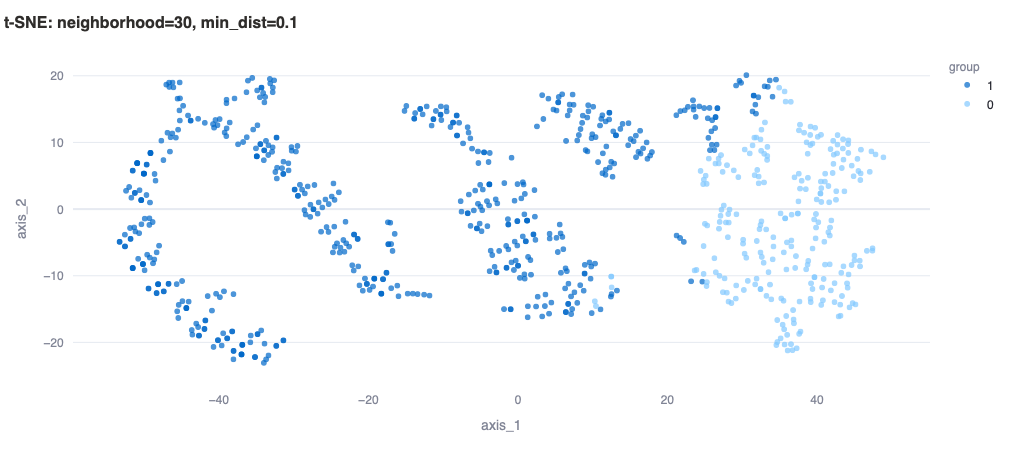

t-SNE: perplexity=10

,method,neighborhood,min_dist,trustworthiness_k10
0,t-SNE,30,NaN,0.995908
1,t-SNE,10,NaN,0.994948


In [10]:
def nonlinear_projection(Z: np.ndarray, seed: int, method: str, neighborhood: int, min_dist: float=0.1) -> dict:
    if method == 't-SNE':
        embedding = TSNE(n_components=2, perplexity=neighborhood, random_state=seed, init='pca', learning_rate='auto', max_iter=1000).fit_transform(Z)
    else:
        from umap import UMAP
        embedding = UMAP(n_neighbors=neighborhood, min_dist=min_dist, random_state=seed, n_jobs=1).fit_transform(Z)
    return dict(embedding=embedding, trustworthiness=float(trustworthiness(Z, embedding, n_neighbors=10)))
projection_rows=[]
embeddings={}
for perplexity in [30,10]:
    result = nonlinear_projection(Z, SEED, "t-SNE", perplexity)
    embeddings[f"tsne_{perplexity}"]=result["embedding"]
    projection_rows.append({"method":"t-SNE","neighborhood":perplexity,"min_dist":np.nan,"trustworthiness_k10":result["trustworthiness"]})
    show_map(result["embedding"],km_labels,f"t-SNE: perplexity={perplexity}")
display(pd.DataFrame(projection_rows))


## Step 10 — UMAP and projection comparison
Use n_neighbors 15 and 30, min_dist .1, seed 42, n_jobs=1. Trustworthiness measures local neighborhood preservation, not classification or cluster accuracy.


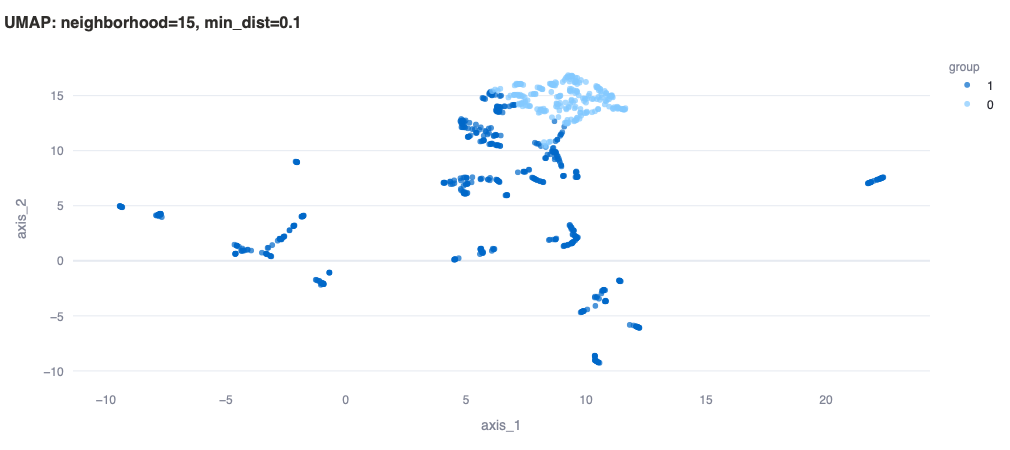

UMAP: neighbors=30, min_dist=0.1

,method,neighborhood,min_dist,trustworthiness_k10
0,t-SNE,30,NaN,0.995908
1,t-SNE,10,NaN,0.994948
2,UMAP,15,0.1,0.990873
3,UMAP,30,0.1,0.986975


PCA quantifies retained variance. t-SNE/UMAP emphasize local structure and depend on parameters and randomness.


In [11]:
for neighbors in [15,30]:
    result = nonlinear_projection(Z, SEED, "UMAP", neighbors, .1)
    embeddings[f"umap_{neighbors}"]=result["embedding"]
    projection_rows.append({"method":"UMAP","neighborhood":neighbors,"min_dist":.1,"trustworthiness_k10":result["trustworthiness"]})
    show_map(result["embedding"],km_labels,f"UMAP: neighbors={neighbors}, min_dist=0.1")
projection_table=pd.DataFrame(projection_rows)
display(projection_table)
print("PCA quantifies retained variance. t-SNE/UMAP emphasize local structure and depend on parameters and randomness.")


## Step 11 — Isolation Forest and comparison with DBSCAN
Contamination sets a cutoff; it is not the measured rate of verified anomalies. Check source records and plausible explanations before any action.


In [12]:
def anomaly_analysis(Z: np.ndarray, seed: int, contamination: float) -> dict:
    flags, scores, rows = ({}, {}, [])
    for c in sorted(set([0.02, 0.05, 0.1, contamination])):
        model = IsolationForest(n_estimators=200, contamination=c, random_state=seed, n_jobs=1).fit(Z)
        flags[c] = model.predict(Z) == -1
        scores[c] = model.decision_function(Z)
        rows.append({'contamination': c, 'flagged': int(flags[c].sum()), 'flagged_fraction': float(flags[c].mean())})
    return dict(flags=flags, scores=scores, sensitivity=pd.DataFrame(rows))
iso=anomaly_analysis(Z,SEED,.05)
display(iso["sensitivity"])
noise=(db_labels==-1)
comparison=[]
for contamination,flag in iso["flags"].items():
    union=int((noise|flag).sum())
    comparison.append({"contamination":contamination,"IF_flags":int(flag.sum()),"DBSCAN_noise":int(noise.sum()),"overlap":int((noise&flag).sum()),"disagreement":int((noise!=flag).sum()),"Jaccard":int((noise&flag).sum())/union if union else np.nan})
display(pd.DataFrame(comparison))
flag=iso["flags"][.05]
category=np.select([flag&noise,flag,noise],["Both","IF only","DBSCAN only"],default="Neither")
show_map(P,category,"Isolation Forest / DBSCAN agreement")
show_chart(px.histogram(pd.DataFrame({"decision_function":iso["scores"][.05],"flag":flag.astype(str)}),x="decision_function",color="flag",nbins=40,title="IF score: lower = more unusual"))
assert int(flag.sum())==40 and int((flag&noise).sum())==34


,contamination,flagged,flagged_fraction
0,0.02,16,0.02
1,0.05,40,0.05
2,0.10,80,0.10


,contamination,IF_flags,DBSCAN_noise,overlap,disagreement,Jaccard
0,0.02,16,42,16,26,0.380952
1,0.05,40,42,34,14,0.708333
2,0.10,80,42,42,38,0.525000


Isolation Forest / DBSCAN agreement

IF score: lower = more unusual

## Step 12 — Combined summary and conclusions
K-Means provides a coarse stable partition, DBSCAN gives a dense group and noise, and IF offers a complementary anomaly view. None establishes verified real categories or anomalies.


In [13]:
summary = frame.copy()
summary["kmeans_cluster"]=km_labels
summary["dbscan_cluster"]=db_labels
summary["IF_flag"]=flag
summary["IF_score"]=iso["scores"][.05]
summary[["PC1","PC2"]]=P
display(summary.head())
OUTPUT_DIR=Path("unsupervised_outputs");OUTPUT_DIR.mkdir(exist_ok=True)
summary.to_csv(OUTPUT_DIR/"summary.csv",index=False)
projection_table.to_csv(OUTPUT_DIR/"projection_diagnostics.csv",index=False)
for name,embedding in embeddings.items():
    pd.DataFrame({"user_id":frame.user_id,"axis_1":embedding[:,0],"axis_2":embedding[:,1],"kmeans_cluster":km_labels}).to_csv(OUTPUT_DIR/(name+".csv"),index=False)
print("Saved summary, projection diagnostics, and all four embedding coordinate files.")
print("Limits: synthetic provenance, MCAR missingness, parameter sensitivity, no verified anomaly labels, no resampling or temporal validation.")
print("Improve with consented real logs, external temporal cohorts, resampling stability, and randomized campaign evaluation.")


,user_id,workouts,streak,notifications,active_next_week,kmeans_cluster,dbscan_cluster,IF_flag,IF_score,PC1,PC2
0,SYN-0001,4.0,3.0,6.0,1,1,0,False,0.180686,0.403964,-0.751407
1,SYN-0002,2.0,9.0,5.0,1,1,0,False,0.175236,0.278637,-0.474262
2,SYN-0003,2.0,12.0,NaN,1,1,0,False,0.168272,0.028405,0.124060
3,SYN-0004,0.0,11.0,10.0,1,1,0,False,0.111758,-0.566979,0.226781
4,SYN-0005,2.0,4.0,12.0,0,1,0,False,0.207551,-0.575227,0.001714


Saved summary, projection diagnostics, and all four embedding coordinate files.
Limits: synthetic provenance, MCAR missingness, parameter sensitivity, no verified anomaly labels, no resampling or temporal validation.
Improve with consented real logs, external temporal cohorts, resampling stability, and randomized campaign evaluation.


## Worksheet answers
1. Exclude the known target so distances and models use current behavior only.
2. Median raw/scaled silhouettes are .7283/.4457, but these are different geometries. Units can dominate raw distances.
3. K=2 maximizes silhouette (.4457), gives clear profiles and stable initializations. The elbow is not uniquely at two.
4. DBSCAN grid: 1–9 clusters, 8–133 noise users. Default: 1 cluster and 42 noise users. A one-cluster silhouette is undefined.
5. PCA retains 81.1137% in 2D. t-SNE/UMAP distort global distances and island sizes.
6. IF and DBSCAN share 34 flags. IF-only=6, DBSCAN-only=8; Jaccard=.7083. Agreement is not ground-truth precision.
7. Important limits: simulated assumptions cannot validate real users; initialization stability cannot establish temporal or resampling robustness.
8. A centroid is an arithmetic mean; inertia is summed squared distance, not accuracy.
9. Check source events/time zones and plausible behavior before interpreting a flag as an error.

Sources: supplied Unsupervised Learning worksheet; archived application data; [scikit-learn clustering](https://scikit-learn.org/stable/modules/clustering.html); [UMAP reproducibility](https://umap-learn.readthedocs.io/en/latest/reproducibility.html).
